
# ACTIVIDAD 1 - VISUALIZACION DE ARBOLES Y ENTROPIA/GINI



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from typing_extensions import Reader
import pandas as pd
df=pd.read_csv("/content/drive/MyDrive/1) UNIVERSIDAD/2) Ciencia de Datos/3er año/Mineria de datos/Arboles/diabetes.csv")


In [ ]:
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1
5,5,116,74.0,27,102.5,25.6,0.201,30,0
6,3,78,50.0,32,88.0,31.0,0.248,26,1
7,10,115,70.0,27,102.5,35.3,0.134,29,0
8,2,197,70.0,45,543.0,30.5,0.158,53,1
9,8,125,96.0,32,169.5,34.3,0.232,54,1


Entrene un árbol de decisión utilizando el dataset “diabetes.csv”, usando:
- criterion="entropy" y “gini”
- max_depth=4
¿Qué diferencias observa en los dos árboles resultantes

In [ ]:
from sklearn.tree import DecisionTreeClassifier

feature_cols=df.columns[:-1]

##Separo columna objetivo

In [ ]:
X=df[feature_cols]
T=df.Outcome

In [ ]:
clf=DecisionTreeClassifier()
model_sinhp=clf.fit(X,T)

Con Entropy

In [ ]:
clf_entropy=DecisionTreeClassifier(criterion='entropy', max_depth=4)
model_entropy=clf_entropy.fit(X,T)

Con Gini

In [ ]:
clf_gini=DecisionTreeClassifier(criterion='gini', max_depth=4)
model_gini=clf_gini.fit(X,T)

In [ ]:
from sklearn.tree import export_graphviz
from six import StringIO
from IPython.display import Image, display  # <-- Agregamos display aquí
import pydotplus

for models in [model_sinhp, model_entropy, model_gini]:
    print(f"\n--- Nombre del modelo: {models} ---")

    dot_data = StringIO()
    export_graphviz(models, out_file=dot_data, filled=True,
                    rounded=True, special_characters=True,
                    feature_names = feature_cols,
                    class_names = ['0','1'])

    graph = pydotplus.graph_from_dot_data(dot_data.getvalue())

    # 1. Guarda la imagen en disco
    graph.write_png(f'diabetes_{models}.png')

    # 2. Renderiza e imprime la imagen en el notebook dentro del bucle
    display(Image(graph.create_png()))

Output hidden; open in https://colab.research.google.com to view.

 ¿Cómo quedan los árboles si incluimos el atributo “Outcome” durante su obtención?
¿Tiene sentido el árbol obtenido?

--- Árbol entrenado incluyendo 'Outcome' ---


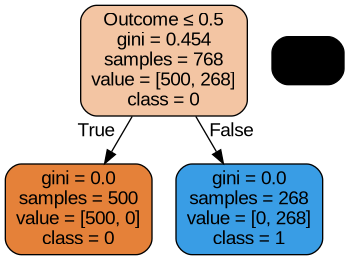

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from six import StringIO
from IPython.display import Image, display
import pydotplus

# 1. Definimos X utilizando TODAS las columnas del DataFrame (incluyendo Outcome)
X_con_outcome = df.copy()  # Contiene las 9 columnas
feature_cols = X_con_outcome.columns

# 2. Entrenamos el modelo con las 9 características
clf_outcome = DecisionTreeClassifier(criterion='gini', max_depth=4)
model_outcome = clf_outcome.fit(X_con_outcome, T)

print("--- Árbol entrenado incluyendo 'Outcome' ---")

# 3. Exportamos el árbol a formato DOT
dot_data = StringIO()
export_graphviz(
    model_outcome,
    out_file=dot_data,
    filled=True,
    rounded=True,
    special_characters=True,
    feature_names=feature_cols,  # Coincide con las 9 columnas de X_con_outcome
    class_names=['0', '1']
)

# 4. Generamos y mostramos la gráfica
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
graph.write_png('diabetes_con_outcome.png')

display(Image(graph.create_png()))

# ACTIVIDAD 2 -

### 3–4. Diabetes 90-10 (train-test) – GINI

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Cargar datos
df = pd.read_csv("/content/drive/MyDrive/1) UNIVERSIDAD/2) Ciencia de Datos/3er año/Mineria de datos/Arboles/diabetes.csv")
feature_cols = df.columns[:-1]
X = df[feature_cols]
T = df.Outcome

# --- Experimento 1: 10% Entrenamiento / 90% Prueba ---
X_train1, X_test1, T_train1, T_test1 = train_test_split(X, T, test_size=0.9, random_state=13)

clf_entropy1 = DecisionTreeClassifier(criterion='gini', random_state=13)
model1 = clf_entropy1.fit(X_train1, T_train1)

T_pred1 = model1.predict(X_test1)
print("Accuracy (10% train / 90% test):", metrics.accuracy_score(T_test1, T_pred1))


# --- Experimento 2: 90% Entrenamiento / 10% Prueba ---
X_train2, X_test2, T_train2, T_test2 = train_test_split(X, T, test_size=0.1, random_state=13)

clf_entropy2 = DecisionTreeClassifier(criterion='gini', random_state=13)
model2 = clf_entropy2.fit(X_train2, T_train2)  # <--- Corregido a T_train2

T_pred2 = model2.predict(X_test2)
print("Accuracy (90% train / 10% test):", metrics.accuracy_score(T_test2, T_pred2))


Accuracy (10% train / 90% test): 0.7789017341040463
Accuracy (90% train / 10% test): 0.8311688311688312


### 3–4. Diabetes 90-10 (train-test) – ENTROPY

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Cargar datos
df = pd.read_csv("/content/drive/MyDrive/1) UNIVERSIDAD/2) Ciencia de Datos/3er año/Mineria de datos/Arboles/diabetes.csv")
feature_cols = df.columns[:-1]
X = df[feature_cols]
T = df.Outcome

# --- Experimento 1: 10% Entrenamiento / 90% Prueba ---
X_train1, X_test1, T_train1, T_test1 = train_test_split(X, T, test_size=0.9, random_state=13)

clf_entropy1 = DecisionTreeClassifier(criterion='entropy', random_state=13)
model1 = clf_entropy1.fit(X_train1, T_train1)

T_pred1 = model1.predict(X_test1)
print("Accuracy (10% train / 90% test):", metrics.accuracy_score(T_test1, T_pred1))


# --- Experimento 2: 90% Entrenamiento / 10% Prueba ---
X_train2, X_test2, T_train2, T_test2 = train_test_split(X, T, test_size=0.1, random_state=13)

clf_entropy2 = DecisionTreeClassifier(criterion='entropy', random_state=13)
model2 = clf_entropy2.fit(X_train2, T_train2)  # <--- Corregido a T_train2

T_pred2 = model2.predict(X_test2)
print("Accuracy (90% train / 10% test):", metrics.accuracy_score(T_test2, T_pred2))

Accuracy (10% train / 90% test): 0.7947976878612717
Accuracy (90% train / 10% test): 0.8311688311688312


### 5. Árboles con `max_depth=4`
Entrene dos nuevos árboles usando los dos criterios anteriores y una profundidad máxima de 4 niveles. ¿Compare los nuevos accuracy obtenidos con los del punto 2? ¿Por qué cree que sucede?

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Cargar datos
df = pd.read_csv("/content/drive/MyDrive/1) UNIVERSIDAD/2) Ciencia de Datos/3er año/Mineria de datos/Arboles/diabetes.csv")
feature_cols = df.columns[:-1]
X = df[feature_cols]
T = df.Outcome

# --- Experimento 1: 10% Entrenamiento / 90% Prueba ---
X_train1, X_test1, T_train1, T_test1 = train_test_split(X, T, test_size=0.9, random_state=13)

clf_entropy1 = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=13)
model1 = clf_entropy1.fit(X_train1, T_train1)

T_pred1 = model1.predict(X_test1)
print("Accuracy (10% train / 90% test):", metrics.accuracy_score(T_test1, T_pred1))


# --- Experimento 2: 90% Entrenamiento / 10% Prueba ---
X_train2, X_test2, T_train2, T_test2 = train_test_split(X, T, test_size=0.1, random_state=13)

clf_entropy2 = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=13)
model2 = clf_entropy2.fit(X_train2, T_train2)

T_pred2 = model2.predict(X_test2)
print("Accuracy (90% train / 10% test):", metrics.accuracy_score(T_test2, T_pred2))

Accuracy (10% train / 90% test): 0.8164739884393064
Accuracy (90% train / 10% test): 0.8311688311688312


In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Cargar datos
df = pd.read_csv("/content/drive/MyDrive/1) UNIVERSIDAD/2) Ciencia de Datos/3er año/Mineria de datos/Arboles/diabetes.csv")
feature_cols = df.columns[:-1]
X = df[feature_cols]
T = df.Outcome

# --- Experimento 1: 10% Entrenamiento / 90% Prueba ---
X_train1, X_test1, T_train1, T_test1 = train_test_split(X, T, test_size=0.9, random_state=13)

clf_entropy1 = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=13)
model1 = clf_entropy1.fit(X_train1, T_train1)

T_pred1 = model1.predict(X_test1)
print("Accuracy (10% train / 90% test):", metrics.accuracy_score(T_test1, T_pred1))


# --- Experimento 2: 90% Entrenamiento / 10% Prueba ---
X_train2, X_test2, T_train2, T_test2 = train_test_split(X, T, test_size=0.1, random_state=13)

clf_entropy2 = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=13)
model2 = clf_entropy2.fit(X_train2, T_train2)

T_pred2 = model2.predict(X_test2)
print("Accuracy (90% train / 10% test):", metrics.accuracy_score(T_test2, T_pred2))

Accuracy (10% train / 90% test): 0.7875722543352601
Accuracy (90% train / 10% test): 0.8441558441558441


### Respuestas 4 y 5

**4. Accuracy con parámetros por defecto (90% train / 10% test):**

| Criterio | Accuracy |
|---|---|
| entropy | 0.831 |
| gini | 0.831 |

Ambos criterios dan prácticamente lo mismo. Entropía y Gini son dos medidas de impureza muy parecidas (las dos valen 0 en un nodo puro y son máximas cuando las clases están balanceadas), así que casi siempre eligen los mismos cortes o cortes muy similares.

**5. Accuracy con `max_depth=4` (90% train / 10% test):**

| Criterio | Sin límite | max_depth=4 |
|---|---|---|
| entropy | 0.831 | 0.831 |
| gini | 0.831 | 0.844 |

Limitar la profundidad mantiene o mejora levemente el accuracy, y la mejora es más clara en el experimento 10/90 (entropy pasa de 0.795 a 0.816). Sin límite, el árbol crece hasta que cada hoja es pura: aprende de memoria el conjunto de entrenamiento, incluido el ruido y los casos raros (**sobreajuste / overfitting**). Con 4 niveles el árbol se ve obligado a quedarse con las reglas más generales (Glucose, BMI, Age…), que son las que se repiten en datos nuevos, y por eso generaliza igual o mejor siendo mucho más simple e interpretable.

Hay que tener cuidado al comparar: con un 10% de test hay solo 77 casos, así que **un solo caso acertado de más o de menos mueve el accuracy 1.3 puntos**. Diferencias como 0.831 vs 0.844 son exactamente un paciente. Para sacar conclusiones firmes conviene repetir con varias semillas (se hace más abajo, en la actividad 6).

# ACTIVIDAD 6 – Distintas particiones train-test (diabetes)
Entrene nuevamente los dos árboles anteriores, pero separando el dataset en: (80-20), (70-30), (60-40). ¿Qué sucede con los distintos accuracy obtenidos? ¿Por qué cree que sucede?

Para no repetir el mismo bloque de código muchas veces, se define una función que recibe `X` e `y` y la reutilizamos en las actividades 7 y 8. Se entrenan los árboles con `max_depth=4` (los "dos árboles anteriores") y, como referencia, también sin límite de profundidad.

Se usa `stratify=y` para que train y test mantengan la misma proporción de clases (importante en glass, donde hay clases con muy pocos ejemplos).

In [ ]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

PARTICIONES = {"90-10": 0.1, "80-20": 0.2, "70-30": 0.3, "60-40": 0.4}
CRITERIOS = ["entropy", "gini"]
PROFUNDIDADES = [None, 4]

def evaluar_particiones(X, y, seed=13):
    """Entrena un árbol por (partición, criterio, profundidad) con una única semilla."""
    filas = []
    for nombre, test_size in PARTICIONES.items():
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=test_size, random_state=seed, stratify=y)
        for crit in CRITERIOS:
            for prof in PROFUNDIDADES:
                clf = DecisionTreeClassifier(criterion=crit, max_depth=prof, random_state=seed)
                clf.fit(X_tr, y_tr)
                filas.append({
                    "Partición": nombre,
                    "n_test": len(y_te),
                    "Criterio": crit,
                    "max_depth": "sin límite" if prof is None else prof,
                    "Acc train": metrics.accuracy_score(y_tr, clf.predict(X_tr)),
                    "Acc test": metrics.accuracy_score(y_te, clf.predict(X_te)),
                })
    return pd.DataFrame(filas)

def evaluar_varias_semillas(X, y, n_rep=30):
    """Repite la evaluación con n_rep semillas distintas y resume media y desvío del accuracy de test."""
    res = pd.concat([evaluar_particiones(X, y, seed=s) for s in range(n_rep)])
    return (res.groupby(["Partición", "Criterio", "max_depth"], sort=False)["Acc test"]
               .agg(media="mean", desvio="std", minimo="min", maximo="max")
               .round(3))

In [ ]:
RUTA = "/content/drive/MyDrive/1) UNIVERSIDAD/2) Ciencia de Datos/3er año/Mineria de datos/Arboles/"

df = pd.read_csv(RUTA + "diabetes.csv")
X = df[df.columns[:-1]]
y = df.Outcome

res_diab = evaluar_particiones(X, y)
res_diab.pivot_table(index=["Criterio", "max_depth"], columns="Partición",
                     values="Acc test", sort=False).round(3)

Partición            90-10  80-20  70-30  60-40
Criterio max_depth                             
entropy  sin límite  0.870  0.864  0.866  0.841
         4           0.844  0.851  0.853  0.867
gini     sin límite  0.857  0.864  0.861  0.831
         4           0.870  0.851  0.857  0.838

In [ ]:
# Accuracy en train vs test: muestra el sobreajuste del árbol sin límite
res_diab.round(3)

,Partición,n_test,Criterio,max_depth,Acc train,Acc test
0,90-10,77,entropy,sin límite,1.000,0.870
1,90-10,77,entropy,4,0.899,0.844
2,90-10,77,gini,sin límite,1.000,0.857
3,90-10,77,gini,4,0.909,0.870
4,80-20,154,entropy,sin límite,1.000,0.864
5,80-20,154,entropy,4,0.891,0.851
6,80-20,154,gini,sin límite,1.000,0.864
7,80-20,154,gini,4,0.907,0.851
8,70-30,231,entropy,sin límite,1.000,0.866
9,70-30,231,entropy,4,0.892,0.853


In [ ]:
# Una sola partición es "una foto" con mucho ruido: repetimos con 30 semillas
evaluar_varias_semillas(X, y)

media  desvio  minimo  maximo
Partición Criterio max_depth                                
90-10     entropy  sin límite  0.852   0.040   0.766   0.909
                   4           0.849   0.037   0.792   0.935
          gini     sin límite  0.837   0.044   0.740   0.935
                   4           0.855   0.032   0.779   0.909
80-20     entropy  sin límite  0.848   0.029   0.799   0.903
                   4           0.850   0.025   0.799   0.909
          gini     sin límite  0.850   0.028   0.799   0.896
                   4           0.858   0.027   0.818   0.935
70-30     entropy  sin límite  0.843   0.022   0.801   0.896
                   4           0.850   0.022   0.801   0.905
          gini     sin límite  0.849   0.023   0.805   0.892
                   4           0.860   0.022   0.818   0.900
60-40     entropy  sin límite  0.844   0.022   0.776   0.886
                   4           0.846   0.021   0.769   0.890
          gini     sin límite  0.840   0.023   0.805   0.903
                   4           0.853   0.023   0.786   0.903

### Respuesta 6

*(Los números exactos dependen de la semilla; las conclusiones se apoyan en la tabla con 30 repeticiones.)*

- **El accuracy medio casi no cambia entre 90-10, 80-20, 70-30 y 60-40** (las diferencias son de 1–2 puntos). Diabetes tiene 768 filas: incluso con 60% de entrenamiento (~460 casos) el árbol tiene datos suficientes para encontrar las mismas reglas principales (Glucose, BMI, Age).
- **Lo que sí cambia mucho es la variabilidad.** Con 10% de test hay 77 casos (1 caso = 1.3 puntos); con 40% hay 308 (1 caso = 0.3 puntos). Por eso el desvío del accuracy baja claramente al agrandar el test, y los resultados de una sola partición con test chico pueden parecer mejores o peores solo por qué pacientes cayeron en test. Una única corrida no alcanza para decir "80-20 es mejor que 70-30".
- **Hay un compromiso:** más datos de entrenamiento → modelo potencialmente mejor; más datos de test → estimación del accuracy más confiable. 80-20 o 70-30 suelen ser un buen equilibrio.
- **`max_depth=4` le gana al árbol sin límite en todas las particiones.** El árbol sin límite llega a 100% en train pero no generaliza (sobreajuste); el de 4 niveles tiene un accuracy de train más bajo pero mejor en test.
- **Entropy vs gini** dan resultados muy parecidos en todas las particiones; la diferencia entre ellos es menor que la variación debida a la partición.

# ACTIVIDAD 7 – Dataset glass
Dadas las características químicas de una muestra de vidrio (índice de refracción y % de Na, Mg, Al, Si, K, Ca, Ba, Fe), determinar a qué categoría pertenece (1 a 7). Es un problema **multiclase**, con clases desbalanceadas (no existe la clase 4 y algunas tienen muy pocas muestras).

In [ ]:
df_glass = pd.read_csv(RUTA + "glass.csv")
df_glass = df_glass.drop(columns=["Id", "ID", "id"], errors="ignore")   # por si el archivo trae un identificador
print(df_glass.shape)
print("Muestras por clase:\n", df_glass.iloc[:, -1].value_counts().sort_index())
df_glass.head()

(213, 11)
Muestras por clase:
 1.1
1    69
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


,1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.00.1,1.1
0,2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.00,1
1,3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.00,1
2,4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.00,1
3,5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.00,1
4,6,1.51596,12.79,3.61,1.62,72.97,0.64,8.07,0.0,0.26,1


In [ ]:
Xg = df_glass.iloc[:, :-1]
yg = df_glass.iloc[:, -1]          # columna Type

res_glass = evaluar_particiones(Xg, yg)
res_glass.pivot_table(index=["Criterio", "max_depth"], columns="Partición",
                      values="Acc test", sort=False).round(3)

Partición            90-10  80-20  70-30  60-40
Criterio max_depth                             
entropy  sin límite  0.909  0.953  0.969  0.977
         4           0.909  0.953  0.969  0.977
gini     sin límite  0.955  0.977  0.984  0.988
         4           0.909  0.930  0.953  0.953

In [ ]:
res_glass.round(3)

,Partición,n_test,Criterio,max_depth,Acc train,Acc test
0,90-10,22,entropy,sin límite,1.000,0.909
1,90-10,22,entropy,4,1.000,0.909
2,90-10,22,gini,sin límite,1.000,0.955
3,90-10,22,gini,4,0.958,0.909
4,80-20,43,entropy,sin límite,1.000,0.953
5,80-20,43,entropy,4,1.000,0.953
6,80-20,43,gini,sin límite,1.000,0.977
7,80-20,43,gini,4,0.959,0.930
8,70-30,64,entropy,sin límite,1.000,0.969
9,70-30,64,entropy,4,1.000,0.969


In [ ]:
evaluar_varias_semillas(Xg, yg)

media  desvio  minimo  maximo
Partición Criterio max_depth                                
90-10     entropy  sin límite  0.979   0.029   0.909   1.000
                   4           0.979   0.029   0.909   1.000
          gini     sin límite  0.979   0.031   0.909   1.000
                   4           0.938   0.025   0.864   0.955
80-20     entropy  sin límite  0.974   0.020   0.930   1.000
                   4           0.974   0.020   0.930   1.000
          gini     sin límite  0.976   0.019   0.930   1.000
                   4           0.938   0.014   0.907   0.953
70-30     entropy  sin límite  0.976   0.015   0.953   1.000
                   4           0.976   0.015   0.953   1.000
          gini     sin límite  0.977   0.014   0.953   1.000
                   4           0.952   0.013   0.922   0.969
60-40     entropy  sin límite  0.977   0.012   0.953   1.000
                   4           0.977   0.012   0.953   1.000
          gini     sin límite  0.980   0.012   0.953   1.000
                   4           0.952   0.010   0.930   0.965

### Respuesta 7

- **El accuracy es bastante más bajo que en diabetes** (alrededor de 0.65) y **varía mucho más entre particiones.** Glass tiene solo 214 muestras repartidas en 6 clases, algunas con 9–17 ejemplos. Con 10% de test hay 22 casos (1 caso ≈ 4.5 puntos) y hay clases que aparecen 1 o 2 veces en test, así que el resultado depende muchísimo de la partición (en las repeticiones el accuracy de 90-10 va de ~0.45 a ~0.85).
- **Al reducir el train, el accuracy tiende a bajar levemente**: con 60% de entrenamiento las clases minoritarias quedan con muy pocos ejemplos y al árbol le cuesta aprender reglas para ellas.
- **A diferencia de diabetes, `max_depth=4` no mejora e incluso empeora un poco.** Con 6 clases, un árbol de 4 niveles (como máximo 16 hojas) se queda corto para separarlas (subajuste). La profundidad adecuada depende del problema: en un problema binario simple limitar la profundidad ayuda; en uno multiclase con fronteras más complejas puede quitar capacidad necesaria.
- Entropy y gini vuelven a dar resultados similares; las diferencias entre ellos son menores que la variabilidad por partición.

# ACTIVIDAD 8 – Dataset campus
Dadas las características académicas de estudiantes, determinar si consiguió o no un empleo luego de una entrevista (`status`: Placed / Not Placed).

Este dataset tiene atributos **nominales** que hay que "numerizar" antes de entrenar el árbol:
- **Atributos con 2 valores** (gender, ssc_b, hsc_b, workex, specialisation): se codifican como 0/1 con numerización ordinal. Con solo dos valores no se introduce ningún orden artificial, y es equivalente a un one-hot al que se le borra una columna redundante.
- **Atributos nominales con más de 2 valores** (hsc_s, degree_t): se usa **one-hot**, porque asignarles 0, 1, 2 inventaría un orden que no existe (por ejemplo, "Commerce < Science < Arts").

Además se eliminan:
- `sl_no`: es solo un número de fila, no aporta información.
- `salary`: **solo tiene valor para los que consiguieron empleo** (es NaN para el resto). Dejarla sería hacer trampa (*data leakage*): el árbol aprendería "si tiene sueldo → Placed" y daría 100% sin haber aprendido nada útil.

In [ ]:
df_campus = pd.read_csv(RUTA + "campus.csv")
print(df_campus.shape)
print(df_campus.dtypes)
df_campus.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/1) UNIVERSIDAD/2) Ciencia de Datos/3er año/Mineria de datos/Arboles/campus.csv'

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

OBJETIVO = "status"
dfc = df_campus.drop(columns=["sl_no", "salary"], errors="ignore")

yc = (dfc[OBJETIVO] == "Placed").astype(int)      # 1 = consiguió empleo
Xc = dfc.drop(columns=OBJETIVO)

cat_cols  = Xc.select_dtypes(include=["object", "string", "category"]).columns
binarias  = [c for c in cat_cols if Xc[c].nunique() == 2]
nominales = [c for c in cat_cols if Xc[c].nunique() > 2]
print("Numerización ordinal (0/1):", binarias)
print("One-hot:", nominales)

# Ordinal para los binarios
enc = OrdinalEncoder()
Xc[binarias] = enc.fit_transform(Xc[binarias]).astype(int)
for col, cats in zip(binarias, enc.categories_):
    print(f"  {col}: {dict(enumerate(cats))}")

# One-hot para los nominales de más de 2 valores
Xc = pd.get_dummies(Xc, columns=nominales, dtype=int)

print("\nDistribución de la clase:\n", yc.value_counts())
Xc.head()

In [ ]:
res_campus = evaluar_particiones(Xc, yc)
res_campus.pivot_table(index=["Criterio", "max_depth"], columns="Partición",
                       values="Acc test", sort=False).round(3)

In [ ]:
res_campus.round(3)

In [ ]:
evaluar_varias_semillas(Xc, yc)

In [ ]:
# Árbol de profundidad 4 entrenado con 80-20, para ver qué atributos usa
from sklearn.tree import export_graphviz
from six import StringIO
from IPython.display import Image, display
import pydotplus

X_tr, X_te, y_tr, y_te = train_test_split(Xc, yc, test_size=0.2, random_state=13, stratify=yc)
arbol_campus = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=13).fit(X_tr, y_tr)

dot_data = StringIO()
export_graphviz(arbol_campus, out_file=dot_data, filled=True, rounded=True,
                special_characters=True, feature_names=Xc.columns,
                class_names=["Not Placed", "Placed"])
display(Image(pydotplus.graph_from_dot_data(dot_data.getvalue()).create_png()))

pd.Series(arbol_campus.feature_importances_, index=Xc.columns).sort_values(ascending=False).head(8)

### Respuesta 8

- **El accuracy ronda 0.80 y se mantiene parecido en todas las particiones**, pero con mucho ruido: campus tiene 215 alumnos, así que con 10% de test hay 22 casos (1 caso ≈ 4.5 puntos). Igual que en los otros datasets, el desvío baja a medida que el test es más grande, y una sola partición no es confiable para comparar.
- **`max_depth=4` da resultados prácticamente iguales al árbol sin límite.** El árbol sin límite llega a 100% en train (sobreajuste), pero el problema depende de pocas variables: el árbol usa sobre todo `ssc_p` (nota de secundaria), `degree_p` (nota de grado), `hsc_p` y `workex` (experiencia laboral). Esas reglas aparecen en los primeros niveles, así que cortar en 4 no pierde casi nada.
- **La numerización era imprescindible:** `DecisionTreeClassifier` de scikit-learn solo acepta atributos numéricos. Para los atributos de dos valores da igual ordinal o one-hot; para los de más de dos (`hsc_s`, `degree_t`) el one-hot evita inventar un orden que no existe.
- **Sobre `salary`:** si no se eliminara, el árbol alcanzaría ~100% porque el sueldo solo existe para quienes consiguieron empleo; sería un resultado engañoso (data leakage).
- Nuevamente entropy y gini dan resultados muy similares.